**1. Objetivo y descripción del conjunto de datos**

Se resume la predicción de FCL(t+1) mediante resultados ya guardados del Sprint 6. Se revisan notebooks 02–08, auditorías y fuentes, comprobando integridad sin ejecutar entrenamientos ni modificar archivos anteriores.

In [1]:
from pathlib import Path
import hashlib,json,platform,sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd().resolve()
if ROOT.name=="notebooks":ROOT=ROOT.parent
assert Path(sys.prefix).name=="tesis-fcl"
NB=ROOT/"notebooks/09_informe_sprint_06.ipynb"
assert (ROOT/"README.md").exists()
protegidos=[ROOT/"README.md",*sorted(p for carpeta in ["data","reports","src","notebooks"] for p in (ROOT/carpeta).rglob("*")
    if p.is_file() and p!=NB and "__pycache__" not in p.parts and ".ipynb_checkpoints" not in p.parts)]
def hashes_previos():return {str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos}
hashes_iniciales=hashes_previos()
fuentes={};secciones_ejecutadas=[];metricas_verificadas=0

def registrar(rel):
    p=ROOT/rel; assert p.is_file(),rel
    fuentes[rel]={"archivo":rel,"sha256":hashlib.sha256(p.read_bytes()).hexdigest()}
    return p

def csv(rel,**kwargs):return pd.read_csv(registrar(rel),float_precision="round_trip",**kwargs)
def js(rel):return json.loads(registrar(rel).read_text(encoding="utf-8"))
def texto(rel):return registrar(rel).read_text(encoding="utf-8")

def verificar_inventario(v,carpeta):
    for name,info in v["inventario"].items():
        p=ROOT/carpeta/name
        assert hashlib.sha256(p.read_bytes()).hexdigest()==info["sha256"],p

def recalcular(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float)
    assert len(y)==len(p) and np.isfinite(y).all() and np.isfinite(p).all()
    e=p-y;sse=np.sum(e*e);sst=np.sum((y-y.mean())**2)
    return {"n":len(y),"MAE":float(np.mean(np.abs(e))),"RMSE":float(np.sqrt(np.mean(e*e))),
        "R2":float(1-sse/sst) if len(y)>1 and sst>0 else np.nan,"error_medio":float(e.mean()),"SSE":float(sse)}

def comprobar_fila(row,g,sufijo=""):
    global metricas_verificadas
    calc=recalcular(g.y_real,g.y_predicho)
    for k in ["MAE","RMSE","R2"]:
        np.testing.assert_allclose(row[k+sufijo],calc[k],rtol=1e-11,atol=1e-7,equal_nan=True)
    assert int(row["n"+sufijo])==len(g)
    metricas_verificadas+=1
    return calc

versiones={p:metadata.version(p) for p in ["pandas","numpy","matplotlib","nbformat","nbclient"]}
plt.rcParams.update({"axes.grid":True,"grid.alpha":.25})
revisados=[]
for p in sorted((ROOT/"notebooks").glob("*.ipynb")):
    if p.name[:2] in ["02","03","04","05","06","07","08"]:
        v=js(str(p.relative_to(ROOT)))
        revisados.append({"archivo":str(p.relative_to(ROOT)),"bloques_codigo":sum(c["cell_type"]=="code" for c in v["cells"]),"tipo":"notebook"})
assert len(revisados)==7
for p in sorted((ROOT/"reports").rglob("*auditoria*.md")):
    rel=str(p.relative_to(ROOT)); contenido=texto(rel)
    revisados.append({"archivo":rel,"bloques_codigo":None,"tipo":"auditoria"})
texto("README.md")
texto("reports/sprint_06/resumen_experimentos.md")
texto("reports/sprint_06/mejoras/resumen_mejoras.md")
v07=js("reports/sprint_06/validacion_baseline.json")
v08=js("reports/sprint_06/mejoras/validacion_mejoras.json")
verificar_inventario(v07,Path("reports/sprint_06"))
verificar_inventario(v08,Path("reports/sprint_06/mejoras"))
raw=csv("data/processed/panel_fcl_preliminar.csv",dtype={"RPJ":"string","RUC":"string"})
fin=csv("data/processed/features_financieras.csv",dtype={"RPJ":"string","RUC":"string"})
macro=csv("data/processed/panel_financiero_macroeconomico.csv",dtype={"RPJ":"string","RUC":"string"})
panel=csv("data/processed/panel_financiero_macro_bursatil.csv",dtype={"RPJ":"string","RUC":"string"})
assert raw.shape==(4221,23) and fin.shape==(4221,57) and macro.shape==(4221,62) and panel.shape==(4221,68)
pd.testing.assert_frame_equal(fin,macro[fin.columns],check_exact=True)
pd.testing.assert_frame_equal(macro,panel[macro.columns],check_exact=True)
elegibles=panel.loc[panel.utilizable_supervisado].copy();elegibles["id_fila"]=elegibles.index
assert len(elegibles)==3560 and elegibles.RPJ.nunique()==309
assert elegibles.particion.value_counts().to_dict()=={"entrenamiento":2869,"prueba":691}
assert elegibles.anio_objetivo.eq(elegibles.Ejercicio+1).all()
assert elegibles.Moneda.eq(elegibles.moneda_objetivo).all()
display(pd.DataFrame([{"conjunto":"Fuente financiera","filas":len(raw),"columnas":raw.shape[1]},
    {"conjunto":"Feature Engineering","filas":len(fin),"columnas":fin.shape[1]},
    {"conjunto":"Financiero + macro","filas":len(macro),"columnas":macro.shape[1]},
    {"conjunto":"Financiero + macro + bolsa","filas":len(panel),"columnas":panel.shape[1]}]))
display(elegibles.groupby(["Moneda","particion"]).agg(n=("RPJ","size"),empresas=("RPJ","nunique"),objetivo_min=("anio_objetivo","min"),objetivo_max=("anio_objetivo","max")))
print("Python:",platform.python_version(),"| Notebooks revisados:",7,"| Auditorias:",sum(r["tipo"]=="auditoria" for r in revisados))
secciones_ejecutadas.append(1)

,conjunto,filas,columnas
0,Fuente financiera,4221,23
1,Feature Engineering,4221,57
2,Financiero + macro,4221,62
3,Financiero + macro + bolsa,4221,68


n  empresas  objetivo_min  objetivo_max
Moneda  particion                                                
D lares entrenamiento   353        49          2006          2021
        prueba           92        26          2022          2025
Soles   entrenamiento  2516       269          2006          2021
        prueba          599       161          2022          2025

Python: 3.12.15 | Notebooks revisados: 7 | Auditorias: 7


El panel conserva 4.221 registros y 336 empresas; el aprendizaje utiliza 3.560 casos de 309 empresas. Entrenamiento tiene 2.869 casos y prueba 691, separados por moneda y año objetivo.

**2. Resumen del EDA**

El EDA examina cobertura, faltantes y distribución del FCL sin eliminar extremos. Los importes se describen por moneda; los estadísticos no se emplean para reajustar predictores o modelos.

,count,min,median,max,skew,faltantes_FCL
Moneda,,,,,,
D lares,506,-1858184.0,23304.0,1909766.0,1.278728,18
Soles,3392,-11333370.0,8891.0,17466182.0,7.659767,305


,moneda,n,min,mediana,max,asimetria,extremos_RIQ
0,D lares,353,-1858184.0,24651.0,1909766.0,1.080578,52
1,Soles,2516,-11333370.0,8934.0,17466182.0,8.273317,484


,registros,empresas,FCL_disponible
Ejercicio,,,
2005,194,194,158
2006,189,189,167
2007,202,202,177
2008,207,207,180
2009,212,212,180
2010,213,213,155
2011,216,216,151
2012,221,221,182
2013,217,217,215


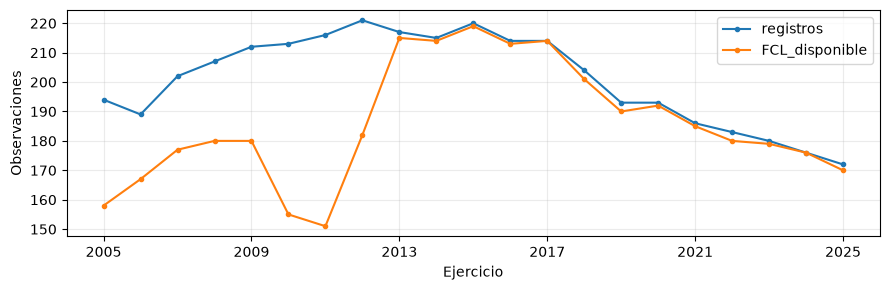

FCL original disponible: 3898 | Faltante: 323


In [2]:
js("notebooks/EDA_FCL_2005_2025.ipynb")
assert raw.RPJ.nunique()==336
assert not raw.duplicated(["RPJ","Ejercicio"]).any()
cobertura=raw.groupby("Ejercicio").agg(registros=("RPJ","size"),empresas=("RPJ","nunique"),FCL_disponible=("FCL_preliminar","count"))
assert cobertura.index.min()==2005 and cobertura.index.max()==2025 and len(cobertura)==21
resumen_eda=raw.groupby("Moneda").FCL_preliminar.agg(["count","min","median","max","skew"])
resumen_eda["faltantes_FCL"]=raw.groupby("Moneda").FCL_preliminar.apply(lambda s:s.isna().sum())
distribucion_train=pd.DataFrame(v07["distribucion_objetivo_train"])
display(resumen_eda)
display(distribucion_train)
display(cobertura)
fig,ax=plt.subplots(figsize=(9,3))
cobertura[["registros","FCL_disponible"]].plot(ax=ax,marker="o",markersize=3)
ax.set(xlabel="Ejercicio",ylabel="Observaciones");ax.set_xticks(range(2005,2026,4));fig.tight_layout();plt.show()
print("FCL original disponible:",int(raw.FCL_preliminar.notna().sum()),"| Faltante:",int(raw.FCL_preliminar.isna().sum()))
secciones_ejecutadas.append(2)

El FCL original está disponible en 3.898 registros y falta en 323. La asimetría y los extremos son importantes; su presencia no justifica retirar observaciones ni mezclar importes de monedas distintas.

**3. Feature Engineering y variable objetivo**

El objetivo es el FCL preliminar de t+1: FCO más CAPEX reportado, invalidado si CAPEX es positivo. De 22 características se documenta un subconjunto de 19 sin tres redundancias lineales; no equivale a FCFF validado.

In [3]:
texto("reports/diccionario_features.md")
texto("reports/trazabilidad_variables.md")
cat=csv("reports/diccionario_integracion_bursatil.csv",keep_default_na=False)
assert cat.variable.tolist()==panel.columns.tolist()
fin22=cat.loc[cat.origen.eq("SMV/Feature Engineering") & cat.predictor_candidato,"variable"].tolist()
redundantes=set(v07["exclusiones_por_redundancia"])
assert len(fin22)==22 and len(redundantes)==3
assert [x for x in fin22 if x not in redundantes]==v07["experimentos"]["E0_financiero"]
futura=fin[["RPJ","Ejercicio","Moneda","FCO","CAPEX_reportado"]].copy()
futura["FCL_siguiente"]=(futura.FCO+futura.CAPEX_reportado).where(~futura.CAPEX_reportado.gt(0))
futura["Ejercicio"]-=1
objetivo=fin[["RPJ","Ejercicio"]].merge(futura[["RPJ","Ejercicio","FCL_siguiente","Moneda"]],on=["RPJ","Ejercicio"],how="left",validate="one_to_one")
np.testing.assert_allclose(fin.objetivo_fcl_t1,objetivo.FCL_siguiente,rtol=0,atol=0,equal_nan=True)
assert fin.moneda_objetivo.fillna("AUSENTE").eq(objetivo.Moneda.fillna("AUSENTE")).all()
assert int(fin.isna().sum().sum())==int(panel[fin.columns].isna().sum().sum())
display(pd.DataFrame([{"bloque":"Ratios","n":8},{"bloque":"Variaciones","n":4},{"bloque":"Temporales","n":10},
    {"bloque":"Financieros seleccionados sin redundancias","n":len(v07["experimentos"]["E0_financiero"])}]))
display(cat.loc[cat.variable.isin([*sorted(redundantes),"objetivo_fcl_t1"]),["variable","metodo","rol_en_dataset"]])
print("Celdas faltantes financieras conservadas:",int(fin.isna().sum().sum()))
secciones_ejecutadas.append(3)

,bloque,n
0,Ratios,8
1,Variaciones,4
2,Temporales,10
3,Financieros seleccionados sin redundancias,19


,variable,metodo,rol_en_dataset
32,fcl_activo,"1 × FCL_preliminar(t) / ActivoTotal(t), denomi...",predictor
39,FCO_mean3_previa,"mean de FCO(t-3), FCO(t-2), FCO(t-1)",predictor
45,FCL_preliminar_mean3_previa,"mean de FCL_preliminar(t-3), FCL_preliminar(t-...",predictor
48,objetivo_fcl_t1,FCL_preliminar de la misma empresa en año t+1 ...,objetivo; EXCLUIR de X


Celdas faltantes financieras conservadas: 20675


Se exportaron 22 características y se usaron 19 en el 07 tras excluir tres redundancias justificadas. Se conservan 20.675 celdas financieras faltantes y el objetivo se verifica mediante una unión exacta a t+1.

**4. Extracción e integración macroeconómica y bursátil**

BCRP aporta indicadores anuales agregados; las integraciones usan Ejercicio = anio, con relación muchos a uno. La identificación SMV no suministra históricos individuales verificados y no se utiliza para asignar cotizaciones al panel.

In [4]:
vma=js("reports/validacion_macroeconomia_bcrp.json")
vi=js("reports/validacion_integracion_datos.json")
vbol=js("reports/validacion_extraccion_bursatil.json")
vib=js("reports/validacion_integracion_bursatil.json")
ma=csv("data/processed/macroeconomia_peru_2005_2025.csv")
bo=csv(vib["entradas"]["bursatil_anual"])
assert ma.shape==(21,6) and bo.shape==(21,17)
for t in [ma,bo]:assert not t.anio.duplicated().any() and sorted(t.anio)==list(range(2005,2026))
for tabla,variables in [(ma,vi["variables_incorporadas"]),(bo,vib["indicadores_incorporados"]+vib["controles_incorporados"])]:
    esperado=tabla.set_index("anio")[variables].reindex(panel.Ejercicio);esperado.index=panel.index
    pd.testing.assert_frame_equal(panel[variables],esperado,check_exact=True)
assert vib["union"]["usa_anio_objetivo"]==False
assert vbol["historicos_individuales_descargados"]==0
assert not cat.set_index("variable").loc["pbi_real_millones_soles_2007","predictor_candidato"]
display(pd.DataFrame([{"etapa":"Macro BCRP","anios":len(ma),"indicadores":ma.shape[1]-1,"panel_columnas":macro.shape[1]},
    {"etapa":"Mercado bursatil anual","anios":len(bo),"indicadores_integrados":len(vib["indicadores_incorporados"]),"controles_integrados":len(vib["controles_incorporados"]),"panel_columnas":panel.shape[1]}]))
display(pd.DataFrame([{"evidencia":"Empresas conservadas en consulta SMV","valor":vbol["empresas_conservadas"]},
    {"evidencia":"Emisores verificados","valor":vbol["emisores_identificados_smv"]},
    {"evidencia":"Historicos individuales descargados","valor":vbol["historicos_individuales_descargados"]},
    {"evidencia":"Años con discrepancias diario/mensual","valor":vbol["anios_discrepancia_rentabilidad_diaria_mensual"]},
    {"evidencia":"Montos diarios negativos originales","valor":vbol["montos_diarios_negativos"]}]))
secciones_ejecutadas.append(4)

,etapa,anios,indicadores,panel_columnas,indicadores_integrados,controles_integrados
0,Macro BCRP,21,5.0,62,NaN,NaN
1,Mercado bursatil anual,21,NaN,68,3.0,3.0


,evidencia,valor
0,Empresas conservadas en consulta SMV,336
1,Emisores verificados,154
2,Historicos individuales descargados,0
3,Años con discrepancias diario/mensual,11
4,Montos diarios negativos originales,3


La integración conserva 62 columnas tras macro y 68 tras bolsa: tres indicadores bursátiles y tres controles. No se integran precios individuales; se documentan 11 años con discrepancias entre frecuencias y tres montos diarios negativos.

**5. Baseline financiero E0**

Ridge financiero usa 19 predictores, alpha=1 y preprocesamiento aprendido en entrenamiento. Se recuperan sus predicciones y se recalculan métricas sin volver a ajustar el modelo.

In [5]:
r07=csv("reports/sprint_06/resultados_experimentos.csv")
c07=csv("reports/sprint_06/comparacion_variantes.csv")
p07=csv("reports/sprint_06/predicciones_baseline.csv",dtype={"RPJ":"string","RUC":"string"})
assert len(p07)==v07["n_predicciones"]==32040
assert not p07.duplicated(["escenario","moneda","experimento","id_fila"]).any()
for row in r07.to_dict(orient="records"):
    g=p07.loc[p07.escenario.eq(row["escenario"]) & p07.moneda.eq(row["moneda"]) & p07.experimento.eq(row["experimento"]) & p07.particion.eq(row["particion"])]
    comprobar_fila(row,g)
    assert int(row["n_predictores"])==len(v07["experimentos"][row["experimento"]])
    assert set(g.id_fila)==set(elegibles.loc[elegibles.Moneda.eq(row["moneda"]) & elegibles.particion.eq(row["particion"]),"id_fila"])
principal=r07.loc[r07.escenario.eq("principal")].copy()
e0=principal.loc[principal.experimento.eq("E0_financiero")]
assert e0.n_predictores.eq(19).all() and e0.alpha.eq(1).all()
display(e0[["moneda","particion","n","n_predictores","MAE","RMSE","R2","error_medio"]].round(4))
secciones_ejecutadas.append(5)

,moneda,particion,n,n_predictores,MAE,RMSE,R2,error_medio
0,D lares,entrenamiento,353,19,110635.6229,2.152702e+05,0.3953,0.0000
1,D lares,prueba,92,19,228054.3656,8.047555e+05,-2.0305,95644.0230
6,Soles,entrenamiento,2516,19,137535.9986,6.034477e+05,0.1799,0.0000
7,Soles,prueba,599,19,379977.4371,1.424709e+06,-1.4901,157975.7289


En prueba, E0 obtiene MAE 379.977 y R² −1,490 en soles; en dólares, MAE 228.054 y R² −2,030. El ajuste computacional es correcto, pero el desempeño fuera de muestra es débil.

**6. Variante macroeconómica E1**

E1 añade inflación, tipo de cambio, tasa de referencia y crecimiento del PBI a las mismas variables financieras. Se conserva la muestra de E0 y se comprueban las métricas y diferencias porcentuales guardadas.

In [6]:
e1=principal.loc[principal.experimento.eq("E1_macroeconomico")]
assert e1.n_predictores.eq(23).all()
assert len(v07["experimentos"]["E1_macroeconomico"])-len(v07["experimentos"]["E0_financiero"])==4
base=e0.set_index(["moneda","particion"])
for exp in ["E1_macroeconomico","E2_bursatil"]:
    comp=c07.loc[c07.escenario.eq("principal")&c07.experimento.eq(exp)]
    for r in comp.to_dict(orient="records"):
        for met in ["MAE","RMSE"]:
            denom=base.loc[(r["moneda"],r["particion"]),met]
            esperado=100*(denom-r[met])/denom if denom!=0 else np.nan
            np.testing.assert_allclose(r[f"mejora_{met}_pct"],esperado,rtol=1e-12,equal_nan=True)
display(e1[["moneda","particion","n","n_predictores","MAE","RMSE","R2"]].round(4))
display(c07.loc[c07.escenario.eq("principal")&c07.experimento.eq("E1_macroeconomico")&c07.particion.eq("prueba"),["moneda","mejora_MAE_pct","mejora_RMSE_pct"]].round(3))
secciones_ejecutadas.append(6)

,moneda,particion,n,n_predictores,MAE,RMSE,R2
2,D lares,entrenamiento,353,23,112972.6985,2.137630e+05,0.4037
3,D lares,prueba,92,23,317991.4029,1.343050e+06,-7.4405
8,Soles,entrenamiento,2516,23,147217.0152,6.024045e+05,0.1827
9,Soles,prueba,599,23,442301.8671,1.445745e+06,-1.5642


,moneda,mejora_MAE_pct,mejora_RMSE_pct
3,D lares,-39.437,-66.889
9,Soles,-16.402,-1.476


E1 tiene 23 predictores y empeora MAE y RMSE de prueba frente a E0 en ambas monedas. Añadir información macroeconómica no produjo una mejora general en esta especificación.

**7. Variante bursátil E2**

E2 incorpora rentabilidad anual, volatilidad y negociación agregada a E1, sin utilizar instrumentos individuales. Se comprueban sus 26 predictores y se mantienen las observaciones originales de evaluación.

In [7]:
e2=principal.loc[principal.experimento.eq("E2_bursatil")]
assert e2.n_predictores.eq(26).all()
externas_bolsa=[x for x in v07["experimentos"]["E2_bursatil"] if x not in v07["experimentos"]["E1_macroeconomico"]]
assert externas_bolsa==vib["indicadores_incorporados"]
for mo in e0.moneda.unique():
    for pa in ["entrenamiento","prueba"]:
        p=p07.loc[p07.escenario.eq("principal")&p07.moneda.eq(mo)&p07.particion.eq(pa)]
        ids=[set(g.id_fila) for _,g in p.groupby("experimento")]
        assert ids[0]==ids[1]==ids[2]
display(pd.DataFrame({"indicador_bursatil":externas_bolsa}))
display(e2[["moneda","particion","n","n_predictores","MAE","RMSE","R2"]].round(4))
secciones_ejecutadas.append(7)

,indicador_bursatil
0,rentabilidad_indice_anual_pct
1,volatilidad_diaria_anualizada_pct
2,monto_renta_variable_anual_millones_pen


,moneda,particion,n,n_predictores,MAE,RMSE,R2
4,D lares,entrenamiento,353,26,115446.8203,2.116589e+05,0.4154
5,D lares,prueba,92,26,237509.5735,7.594931e+05,-1.6992
10,Soles,entrenamiento,2516,26,147298.4535,6.020621e+05,0.1837
11,Soles,prueba,599,26,426780.0103,1.438297e+06,-1.5379


E2 mejora el RMSE de prueba en dólares frente a E0 (759.493 frente a 804.755), pero empeora su MAE. En soles no supera a E0 en ninguno de ambos errores; sus R² principales siguen negativos.

**8. Comparación de MAE, RMSE y R²**

MAE resume error absoluto, RMSE pondera más los errores grandes y R² compara SSE con la variación respecto a la media del conjunto evaluado. Se presentan resultados por moneda sin promediar importes heterogéneos.

,moneda,experimento,n,MAE,RMSE,R2
1,D lares,E0_financiero,92,228054.3656,8.047555e+05,-2.0305
3,D lares,E1_macroeconomico,92,317991.4029,1.343050e+06,-7.4405
5,D lares,E2_bursatil,92,237509.5735,7.594931e+05,-1.6992
7,Soles,E0_financiero,599,379977.4371,1.424709e+06,-1.4901
9,Soles,E1_macroeconomico,599,442301.8671,1.445745e+06,-1.5642
11,Soles,E2_bursatil,599,426780.0103,1.438297e+06,-1.5379


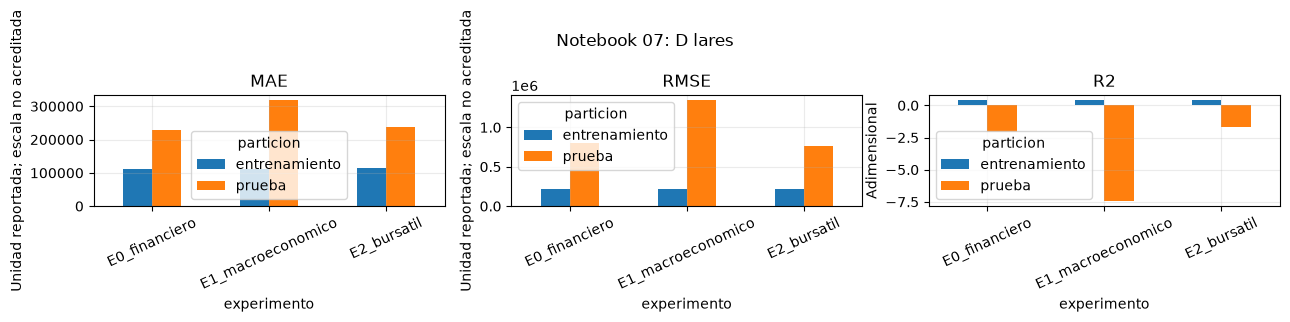

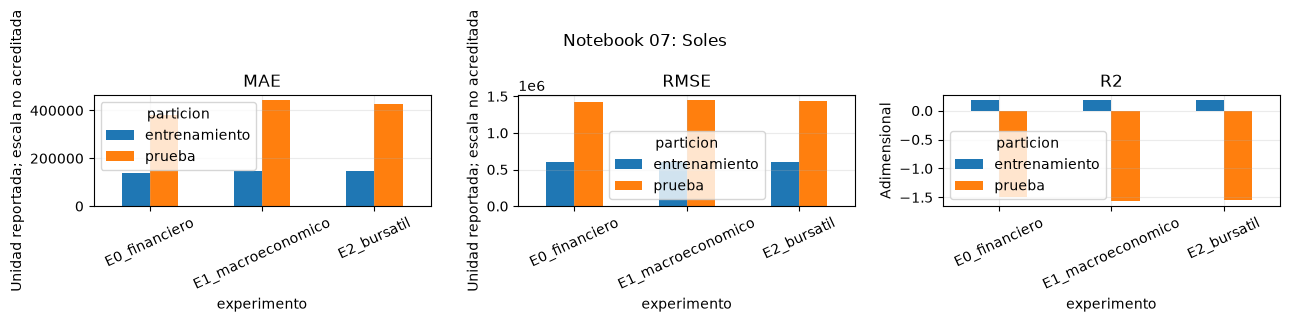

In [8]:
prueba07=principal.loc[principal.particion.eq("prueba")].copy()
assert prueba07.R2.lt(0).all()
assert prueba07.groupby("moneda").n.nunique().eq(1).all()
display(prueba07[["moneda","experimento","n","MAE","RMSE","R2"]].round(4))
for mo in sorted(prueba07.moneda.unique()):
    fig,axs=plt.subplots(1,3,figsize=(13,3))
    tab=principal.loc[principal.moneda.eq(mo)]
    for ax,met in zip(axs,["MAE","RMSE","R2"]):
        tab.pivot(index="experimento",columns="particion",values=met).plot.bar(ax=ax,rot=25)
        ax.set(title=met,ylabel="Adimensional" if met=="R2" else "Unidad reportada; escala no acreditada")
    fig.suptitle(f"Notebook 07: {mo}");fig.tight_layout();plt.show()
secciones_ejecutadas.append(8)

Los seis modelos principales tienen R² negativos en prueba. E0 alcanza el menor MAE en ambas monedas y el menor RMSE en soles; E2 alcanza el menor RMSE en dólares, sin superioridad global.

**9. Diagnóstico de los resultados negativos**

Se examina cuánto SSE concentran los errores grandes y la banca, sin eliminar filas ni volver a seleccionar modelos. El diagnóstico muestra sensibilidad y heterogeneidad, pero no prueba causalidad económica.

In [9]:
diag=p07.loc[p07.escenario.eq("principal")&p07.experimento.eq("E0_financiero")&p07.particion.eq("prueba")].copy()
diag=diag.merge(elegibles[["id_fila","NombreEmpresa","crecimiento_ActivoTotal"]],on="id_fila",how="left",validate="one_to_one")
diag["SSE_fila"]=(diag.y_predicho-diag.y_real)**2
concentracion=[];principales_errores=[]
for mo,g in diag.groupby("moneda"):
    total=g.SSE_fila.sum();top=g.nlargest(1,"SSE_fila").iloc[0]
    banco=g.TipoSector.eq("BANCOS")
    concentracion.append({"moneda":mo,"n":len(g),"casos_bancarios":int(banco.sum()),"SSE_bancos_pct":100*g.loc[banco,"SSE_fila"].sum()/total,"SSE_mayor_error_pct":100*top.SSE_fila/total})
    principales_errores.append({"moneda":mo,"RPJ":top.RPJ,"empresa":top.NombreEmpresa,"Ejercicio":top.Ejercicio,"objetivo":top.anio_objetivo,
        "crecimiento_activos":top.crecimiento_ActivoTotal,"y_real":top.y_real,"y_predicho":top.y_predicho})
concentracion=pd.DataFrame(concentracion)
display(concentracion.round(4))
display(pd.DataFrame(principales_errores))
col07=csv("reports/sprint_06/diagnostico_colinealidad.csv")
cal07=csv("reports/sprint_06/diagnostico_entrenamiento.csv")
assert col07.rango.eq(col07.n_predictores).all()
display(col07[["moneda","experimento","n_predictores","rango","numero_condicion","anios_train"]].round(3))
secciones_ejecutadas.append(9)

,moneda,n,casos_bancarios,SSE_bancos_pct,SSE_mayor_error_pct
0,D lares,92,0,0.0000,80.5822
1,Soles,599,82,95.2566,23.4465


,moneda,RPJ,empresa,Ejercicio,objetivo,crecimiento_activos,y_real,y_predicho
0,D lares,L02127,INVERSIONES PORTUARIAS CHANCAY S.A.A.,2024,2025,486.402640,0.0,6.929111e+06
1,Soles,B80004,BANCO BBVA PERU,2022,2023,-0.034319,686948.0,1.757107e+07


,moneda,experimento,n_predictores,rango,numero_condicion,anios_train
0,D lares,E0_financiero,19,19,13.822,16
1,D lares,E1_macroeconomico,23,23,13.881,16
2,D lares,E2_bursatil,26,26,14.008,16
3,Soles,E0_financiero,19,19,210.546,16
4,Soles,E1_macroeconomico,23,23,215.099,16
5,Soles,E2_bursatil,26,26,221.434,16


En dólares, una fila concentra aproximadamente 80,58 % del SSE de E0; en soles, BANCOS concentra 95,26 %. Son diagnósticos sobre errores observados, no razones para retirar esos casos de prueba.

**10. Mejoras del 08 y resultados bancarios y no bancarios**

El 08 añade baselines ingenuos, clipping p1/p99 y selección de alpha por validación temporal. Se comprueban la selección congelada y las métricas sectoriales, conservando el deterioro bancario y sin reentrenar modelos.

In [10]:
r08=csv("reports/sprint_06/mejoras/metricas_mejoras.csv")
p08=csv("reports/sprint_06/mejoras/predicciones_mejoras.csv",dtype={"RPJ":"string","RUC":"string"})
seleccion=csv("reports/sprint_06/mejoras/seleccion_congelada_cv.csv")
politica=csv("reports/sprint_06/mejoras/metricas_politica_cv.csv")
psel=csv("reports/sprint_06/mejoras/predicciones_seleccionadas_cv.csv",dtype={"RPJ":"string","RUC":"string"})
sector=csv("reports/sprint_06/mejoras/comparacion_sector_vs07.csv")
cv_anual=csv("reports/sprint_06/mejoras/cv_por_anio.csv")
cv_scores=csv("reports/sprint_06/mejoras/cv_puntuaciones.csv")
optimos=csv("reports/sprint_06/mejoras/alphas_optimos.csv")
limites_clip=csv("reports/sprint_06/mejoras/umbrales_clipping.csv")
param_naive=csv("reports/sprint_06/mejoras/parametros_ingenuos.csv")
assert len(limites_clip)==v08["n_modelos_ridge"]*11==495
assert len(r08)==110 and len(p08)==v08["n_predicciones"]
for row in r08.to_dict(orient="records"):
    g=p08.loc[p08.moneda.eq(row["moneda"])&p08.grupo_ajuste.eq(row["grupo_ajuste"])&p08.especificacion.eq(row["especificacion"])&p08.experimento.eq(row["experimento"])&p08.particion.eq(row["particion"])]
    calc=comprobar_fila(row,g)
    if row["particion"]=="prueba":
        for met,denom in [("R2_OOS_media","SSE_media"),("R2_OOS_persistencia","SSE_persistencia")]:
            referencia=p08.loc[p08.moneda.eq(row["moneda"])&p08.grupo_ajuste.eq(row["grupo_ajuste"])&p08.especificacion.eq("ingenuo")&p08.experimento.eq("media_train" if "media" in met else "persistencia_t")&p08.particion.eq("prueba")].set_index("id_fila").loc[g.id_fila]
            d=float(np.sum((g.y_real.to_numpy()-referencia.y_predicho.to_numpy())**2))
            np.testing.assert_allclose(row[denom],d,rtol=1e-11)
            np.testing.assert_allclose(row[met],1-calc["SSE"]/d if d>0 else np.nan,rtol=1e-11,atol=1e-10,equal_nan=True)
# Seleccion derivada exclusivamente de puntuaciones de validacion guardadas.
puntos=cv_anual.groupby(["moneda","grupo","especificacion","experimento","alpha"],as_index=False).mse.mean().rename(columns={"mse":"mse_cv"})
ver=cv_scores.merge(puntos,on=["moneda","grupo","especificacion","experimento","alpha"],suffixes=("_guardado","_recalculado"),validate="one_to_one")
np.testing.assert_allclose(ver.mse_cv_guardado,ver.mse_cv_recalculado,rtol=1e-12)
opt_re=puntos.sort_values(["mse_cv","alpha"],ascending=[True,False],kind="stable").drop_duplicates(["moneda","grupo","especificacion","experimento"])
gan_re=opt_re.sort_values(["mse_cv","alpha","especificacion","experimento"],ascending=[True,False,True,True],kind="stable").drop_duplicates(["moneda","grupo"])
a=seleccion[["moneda","grupo","especificacion","experimento","alpha"]].sort_values(["moneda","grupo"]).reset_index(drop=True)
z=gan_re[a.columns].sort_values(["moneda","grupo"]).reset_index(drop=True)
pd.testing.assert_frame_equal(a,z,check_exact=True)
ids_test=set(elegibles.loc[elegibles.particion.eq("prueba"),"id_fila"])
for fold in v08["pliegues"]:
    assert not ids_test.intersection(fold["ids_train"]+fold["ids_validacion"])
    assert max(fold["anios_train"])<min(fold["anios_validacion"])
assert psel.id_fila.is_unique and len(psel)==3560
assert set(psel.loc[psel.particion.eq("prueba"),"id_fila"])==ids_test
for row in politica.to_dict(orient="records"):
    g=psel.loc[psel.moneda.eq(row["moneda"])&psel.particion.eq(row["particion"])]
    comprobar_fila(row,g)
for row in sector.to_dict(orient="records"):
    gr=psel.grupo_bancario.eq(row["grupo_ajuste"])
    g=psel.loc[psel.moneda.eq(row["moneda"])&psel.particion.eq(row["particion"])&gr]
    comprobar_fila(row,g,"_08")
display(seleccion)
display(sector.loc[sector.particion.eq("prueba"),["moneda","grupo_ajuste","n_08","MAE_07","MAE_08","RMSE_07","RMSE_08","R2_07","R2_08","R2_OOS_media_08","R2_OOS_persistencia_08"]].round(4))
display(politica.loc[politica.particion.eq("prueba"),["moneda","n","MAE","RMSE","R2","R2_OOS_media","R2_OOS_persistencia"]].round(4))
secciones_ejecutadas.append(10)

,moneda,grupo,especificacion,experimento,alpha,rmse_cv
0,D lares,no_bancario,niveles_t_externos_t_1,E1_macroeconomico,1000.0,2.704516e+05
1,D lares,todas,niveles_t_externos_t_1,E1_macroeconomico,1000.0,2.704516e+05
2,Soles,no_bancario,sin_niveles_t_externos_t_1,E2_bursatil,1000.0,3.384358e+05
3,Soles,todas,niveles_t_externos_t,E1_macroeconomico,10.0,8.446541e+05
4,Soles,bancario,niveles_t_externos_t_1,E1_macroeconomico,10.0,2.886677e+06


,moneda,grupo_ajuste,n_08,MAE_07,MAE_08,RMSE_07,RMSE_08,R2_07,R2_08,R2_OOS_media_08,R2_OOS_persistencia_08
1,D lares,no_bancario,92,2.280544e+05,1.478733e+05,8.047555e+05,3.239768e+05,-2.0305,0.5089,0.5141,0.1185
3,Soles,bancario,82,1.972879e+06,4.299570e+06,3.758202e+06,5.683161e+06,-1.8360,-5.4853,-5.4850,-2.3277
5,Soles,no_bancario,517,1.273315e+05,1.247513e+05,3.339961e+05,2.802392e+05,0.2349,0.4614,0.4811,0.4480


,moneda,n,MAE,RMSE,R2,R2_OOS_media,R2_OOS_persistencia
1,D lares,92,147873.2512,3.239768e+05,0.5089,0.5141,0.1185
3,Soles,599,696262.3068,2.118786e+06,-4.5074,-4.4558,-2.0929


Los no bancarios mejoran: R² 0,509 en dólares y 0,461 en soles. BANCOS empeora a −5,485 y arrastra el total de soles a −4,507; se conserva la selección de CV, sin sustituirla mirando prueba.

**11. Limitaciones metodológicas del Sprint**

Se distinguen integridad estadística, disponibilidad real y validez económica del objetivo. La prueba ya examinada durante el rediseño no constituye una nueva evaluación independiente, aunque alpha se haya elegido dentro del entrenamiento.

In [11]:
assert v07["disponibilidad_real_historica"]=="NO_VERIFICADA"
assert v08["disponibilidad_temporal_real"]=="NO_VERIFICADA"
assert v08["prueba_independiente_del_rediseño"]==False
assert v07["escala_monetaria"]=="NO_ACREDITADA"
folds=pd.DataFrame(v08["pliegues"])
resumen_folds=folds.groupby(["moneda","grupo"]).agg(folds=("fold","nunique"),n_train_min=("n_train","min"),n_validacion_total=("n_validacion","sum"))
ruc_no11=int((~panel.RUC.str.fullmatch(r"\d{11}",na=False)).sum())
limitaciones=pd.DataFrame([
    {"dimension":"Disponibilidad temporal","estado":"NO_VERIFICADA","evidencia":"Sin fechas efectivas de pronostico/publicacion ni vintages; rezagar no elimina revisiones."},
    {"dimension":"Escala monetaria","estado":"NO_ACREDITADA","evidencia":"Modelos por moneda; no se certifica homogeneidad de escala entre empresas."},
    {"dimension":"Objetivo financiero","estado":"APROXIMACION","evidencia":"FCO + CAPEX, no FCFF validado; definicion especialmente limitada en banca y otros intermediarios."},
    {"dimension":"Dimension temporal","estado":"REDUCIDA","evidencia":"16 años de entrenamiento general; banca 9, con dos folds frente a cuatro en otras cohortes."},
    {"dimension":"Prueba independiente","estado":"PENDIENTE","evidencia":"2022–2025 ya examinado en 07/auditoria; rediseño requiere confirmacion futura nueva."},
    {"dimension":"Fuentes bursatiles","estado":"LIMITACIONES_DOCUMENTADAS","evidencia":"Transicion 2015 y discrepancias entre frecuencias; sin historicos individuales obtenidos."},
    {"dimension":"Identificadores","estado":"ANOMALIA_PRESERVADA","evidencia":f"{ruc_no11} filas con RUC distinto de 11 digitos, sin completar ni excluir empresas."},
    {"dimension":"Dependencia y generalizacion","estado":"NO_CERTIFICADA","evidencia":"Empresas repetidas y variables anuales comunes; diferencias de metricas no demuestran significancia ni causalidad."},
])
assert ruc_no11==63
display(resumen_folds)
display(limitaciones)
print("Caveat: los dictamenes tecnicos de auditoria no acreditan por si solos publicacion historica o utilidad operativa.")
secciones_ejecutadas.append(11)

folds  n_train_min  n_validacion_total
moneda  grupo                                              
D lares no_bancario      4          154                 199
        todas            4          154                 199
Soles   bancario         2           93                  79
        no_bancario      4         1138                1206
        todas            4         1155                1361

,dimension,estado,evidencia
0,Disponibilidad temporal,NO_VERIFICADA,Sin fechas efectivas de pronostico/publicacion...
1,Escala monetaria,NO_ACREDITADA,Modelos por moneda; no se certifica homogeneid...
2,Objetivo financiero,APROXIMACION,"FCO + CAPEX, no FCFF validado; definicion espe..."
3,Dimension temporal,REDUCIDA,"16 años de entrenamiento general; banca 9, con..."
4,Prueba independiente,PENDIENTE,2022–2025 ya examinado en 07/auditoria; redise...
5,Fuentes bursatiles,LIMITACIONES_DOCUMENTADAS,Transicion 2015 y discrepancias entre frecuenc...
6,Identificadores,ANOMALIA_PRESERVADA,"63 filas con RUC distinto de 11 digitos, sin c..."
7,Dependencia y generalizacion,NO_CERTIFICADA,Empresas repetidas y variables anuales comunes...


Caveat: los dictamenes tecnicos de auditoria no acreditan por si solos publicacion historica o utilidad operativa.


La ejecución y las particiones están verificadas, pero faltan escala y disponibilidad histórica acreditadas. La evidencia es retrospectiva y condicional; no permite afirmar utilidad operativa ni mejoras generalizables sin una evaluación nueva.

**12. Conclusiones y reproducibilidad del informe**

Se resumen los hallazgos a partir de las métricas comprobadas y se verifica la preservación de todos los archivos anteriores. El informe solo lee fuentes y recalcula estadísticas; no ajusta ni selecciona nuevos modelos.

In [12]:
assert secciones_ejecutadas==list(range(1,12))
assert metricas_verificadas==len(r07)+len(r08)+len(politica)+len(sector)
assert len(ids_test)==691 and len(elegibles)==3560
assert prueba07.R2.lt(0).all()
corp=sector.loc[sector.particion.eq("prueba")&sector.grupo_ajuste.eq("no_bancario")]
assert corp.R2_08.gt(corp.R2_07).all()
assert corp.R2_OOS_media_08.gt(0).all() and corp.R2_OOS_persistencia_08.gt(0).all()
banca=sector.loc[sector.particion.eq("prueba")&sector.grupo_ajuste.eq("bancario")]
assert len(banca)==1 and banca.RMSE_08.iloc[0]>banca.RMSE_07.iloc[0]
conclusiones=pd.DataFrame([
    {"resultado":"Integridad de datos","evidencia":"4221 registros; 3560 elegibles; 691 casos de prueba preservados."},
    {"resultado":"Ridge 07","evidencia":"R2 de prueba negativos en E0, E1 y E2; añadir externos no mejora de forma general."},
    {"resultado":"Mejoras no bancarias 08","evidencia":"Ganadores de CV superan E0 del 07 y ambos ingenuos en SSE por moneda."},
    {"resultado":"Banca 08","evidencia":"Deterioro de prueba; se mantiene configuracion elegida por CV y se reporta el resultado negativo."},
    {"resultado":"Cierre del Sprint","evidencia":"Referencia experimental reproducible; pendientes disponibilidad, escala y validacion independiente."},
])
fuentes_df=pd.DataFrame(fuentes.values()).sort_values("archivo").reset_index(drop=True)
assert all(hashlib.sha256((ROOT/r.archivo).read_bytes()).hexdigest()==r.sha256 for r in fuentes_df.itertuples(index=False))
assert hashes_previos()==hashes_iniciales,"Un archivo anterior fue modificado"
verificacion_reporte={"secciones":12,"celdas_codigo":12,"filas_metricas_recalculadas":metricas_verificadas,
    "archivos_leidos":len(fuentes_df),"sin_entrenamientos":True,"sin_archivos_anteriores_modificados":True,
    "test_original_preservado":691,"fuentes":fuentes_df.to_dict(orient="records")}
display(conclusiones)
display(fuentes_df.loc[fuentes_df.archivo.str.startswith("reports/sprint_06/") & fuentes_df.archivo.str.endswith((".csv",".json")),["archivo"]])
print("Secciones verificadas:",12,"| Celdas de codigo:",12,"| Filas de metricas recalculadas:",metricas_verificadas)
print("Fuentes leidas:",len(fuentes_df),"| Entrenamientos:",0,"| Modificaciones de archivos anteriores:",0)
secciones_ejecutadas.append(12)

,resultado,evidencia
0,Integridad de datos,4221 registros; 3560 elegibles; 691 casos de p...
1,Ridge 07,"R2 de prueba negativos en E0, E1 y E2; añadir ..."
2,Mejoras no bancarias 08,Ganadores de CV superan E0 del 07 y ambos inge...
3,Banca 08,Deterioro de prueba; se mantiene configuracion...
4,Cierre del Sprint,Referencia experimental reproducible; pendient...


,archivo
24,reports/sprint_06/comparacion_variantes.csv
25,reports/sprint_06/diagnostico_colinealidad.csv
26,reports/sprint_06/diagnostico_entrenamiento.csv
27,reports/sprint_06/mejoras/alphas_optimos.csv
28,reports/sprint_06/mejoras/comparacion_sector_v...
29,reports/sprint_06/mejoras/cv_por_anio.csv
30,reports/sprint_06/mejoras/cv_puntuaciones.csv
31,reports/sprint_06/mejoras/metricas_mejoras.csv
32,reports/sprint_06/mejoras/metricas_politica_cv...
33,reports/sprint_06/mejoras/parametros_ingenuos.csv


Secciones verificadas: 12 | Celdas de codigo: 12 | Filas de metricas recalculadas: 156
Fuentes leidas: 49 | Entrenamientos: 0 | Modificaciones de archivos anteriores: 0


El Sprint entrega una referencia reproducible, no una mejora universal: los no bancarios avanzan y la banca sigue pendiente. Se verifican 156 filas de métricas sin reentrenar modelos ni modificar resultados anteriores.